In [7]:
import matplotlib.pyplot as plt
import seaborn as sns
import os
import pandas as pd

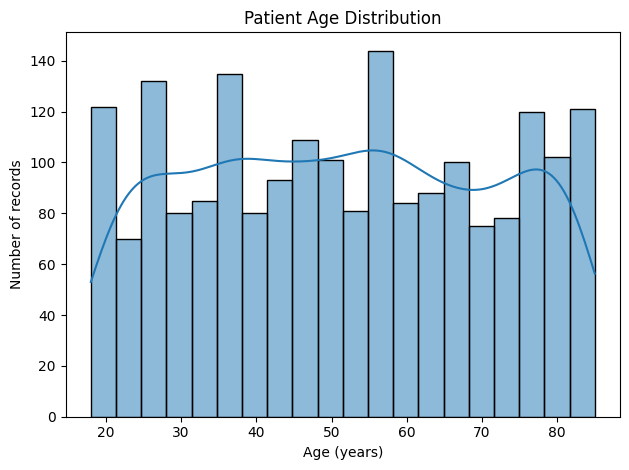

In [27]:
# 6.1 Patient age histogram

df = pd.read_csv("healthcare_cleaned.csv")

os.makedirs("../visualizations", exist_ok=True)

sns.histplot(data=df, x="age", bins=20, kde=True)
plt.title("Patient Age Distribution")
plt.xlabel("Age (years)")
plt.ylabel("Number of records")
plt.tight_layout()
plt.savefig("../visualizations/01_patient_age_histogram.png", dpi=150)
plt.show()
plt.close()

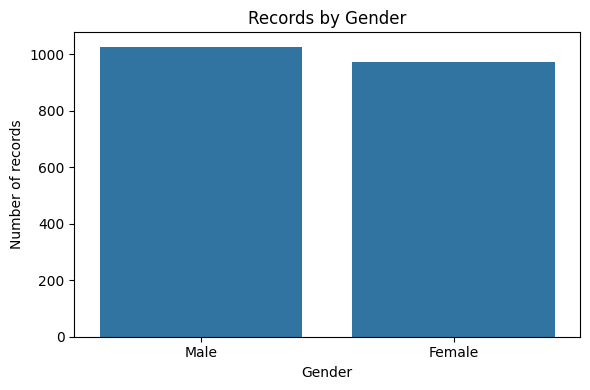

In [28]:
# Chart 2: records by gender
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x="gender",
              order=df["gender"].value_counts().index)
plt.title("Records by Gender")
plt.xlabel("Gender")
plt.ylabel("Number of records")
plt.tight_layout()
plt.savefig("../visualizations/02_gender_count.png", dpi=150)
plt.show()
plt.close()



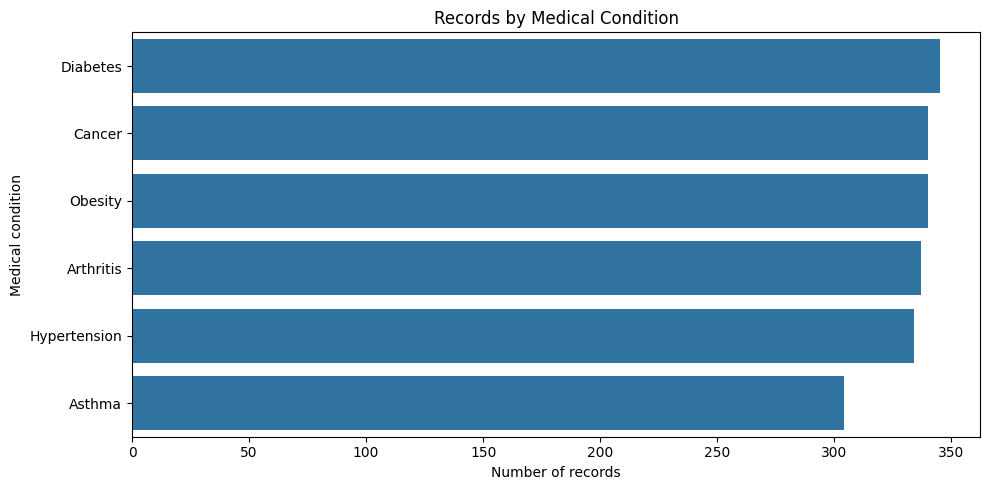

In [29]:
# Chart 3: records by medical condition
plt.figure(figsize=(10, 5))
condition_order = df["medical_condition"].value_counts().index
sns.countplot(data=df, y="medical_condition", order=condition_order)
plt.title("Records by Medical Condition")
plt.xlabel("Number of records")
plt.ylabel("Medical condition")
plt.tight_layout()
plt.savefig("../visualizations/03_disease_bar.png", dpi=150)
plt.show()
plt.close()

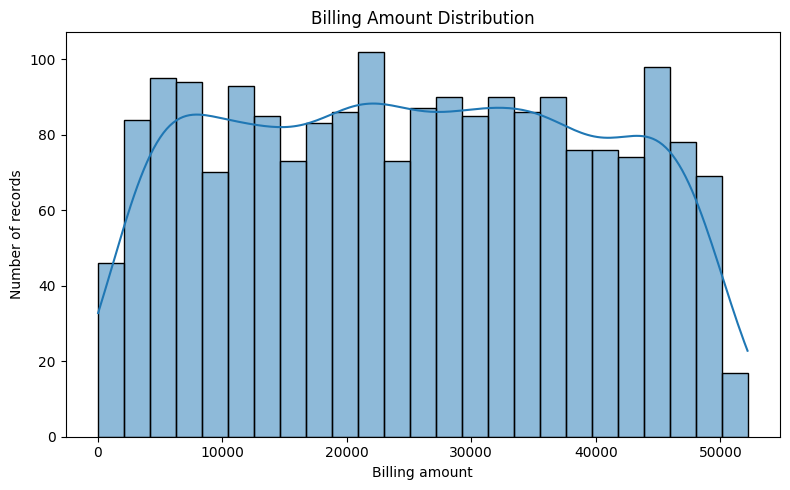

In [30]:
# Create the hospital stay column (run this once, before chart 5)
df["date_of_admission"] = pd.to_datetime(df["date_of_admission"])
df["discharge_date"] = pd.to_datetime(df["discharge_date"])
df["hospital_stay_days"] = (
    df["discharge_date"] - df["date_of_admission"]
).dt.days

# Chart 4: billing amount distribution
plt.figure(figsize=(8, 5))
sns.histplot(data=df, x="billing_amount", bins=25, kde=True)
plt.title("Billing Amount Distribution")
plt.xlabel("Billing amount")
plt.ylabel("Number of records")
plt.tight_layout()
plt.savefig("../visualizations/04_billing_amount_histogram.png", dpi=150)
plt.show()
plt.close()



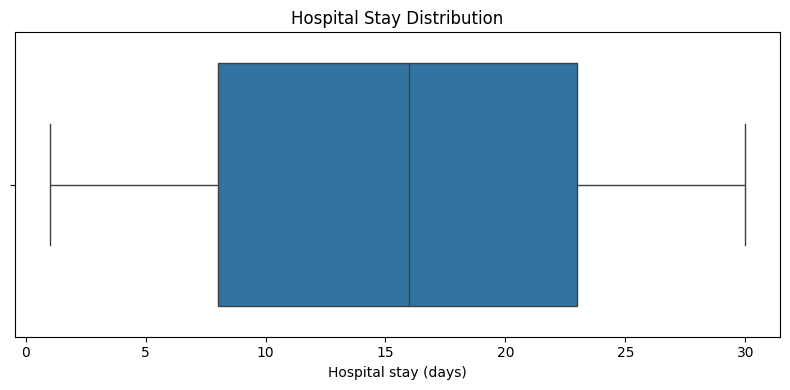

In [31]:
# Chart 5: hospital stay boxplot
plt.figure(figsize=(8, 4))
sns.boxplot(data=df, x="hospital_stay_days")
plt.title("Hospital Stay Distribution")
plt.xlabel("Hospital stay (days)")
plt.tight_layout()
plt.savefig("../visualizations/05_hospital_stay_boxplot.png", dpi=150)
plt.show()
plt.close()

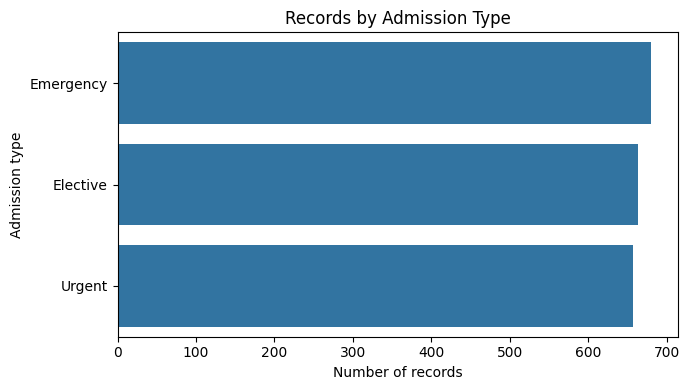

In [32]:
# 6.4 Department count and recovery pie chart
# Chart 6: records by admission type
plt.figure(figsize=(7, 4))
sns.countplot(data=df, y="admission_type",
              order=df["admission_type"].value_counts().index)
plt.title("Records by Admission Type")
plt.xlabel("Number of records")
plt.ylabel("Admission type")
plt.tight_layout()
plt.savefig("../visualizations/06_admission_type_count.png", dpi=150)
plt.show()
plt.close()



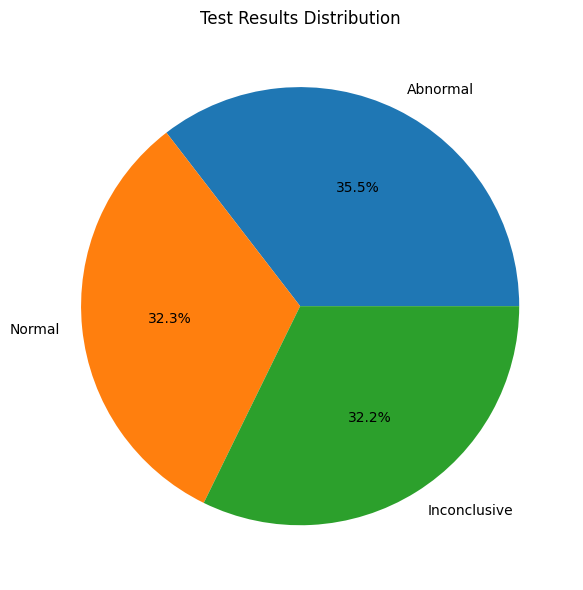

In [33]:
# Chart 7: test results pie
plt.figure(figsize=(6, 6))
df["test_results"].value_counts().plot(
    kind="pie", autopct="%1.1f%%", ylabel=""
)
plt.title("Test Results Distribution")
plt.tight_layout()
plt.savefig("../visualizations/07_test_results_pie.png", dpi=150)
plt.show()
plt.close()

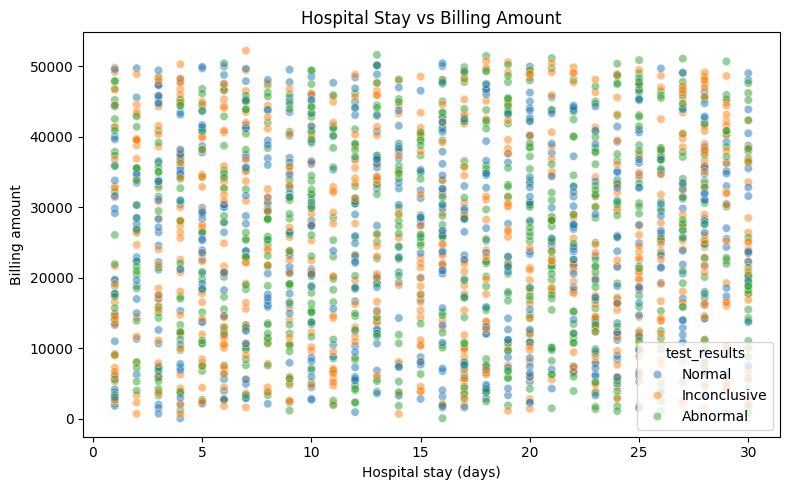

In [34]:
# Chart 8: stay vs billing scatter
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x="hospital_stay_days",
                y="billing_amount", hue="test_results", alpha=0.5)
plt.title("Hospital Stay vs Billing Amount")
plt.xlabel("Hospital stay (days)")
plt.ylabel("Billing amount")
plt.tight_layout()
plt.savefig("../visualizations/08_stay_billing_scatter.png", dpi=150)
plt.show()
plt.close()





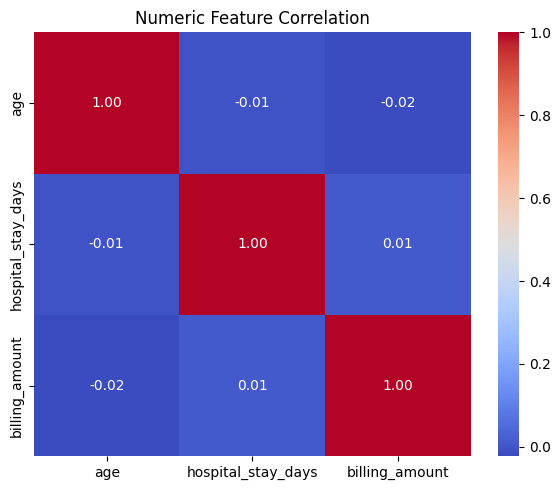

In [35]:
# Chart 9: correlation heatmap
plt.figure(figsize=(6, 5))
sns.heatmap(
    df[["age", "hospital_stay_days", "billing_amount"]].corr(),
    annot=True, cmap="coolwarm", fmt=".2f"
)
plt.title("Numeric Feature Correlation")
plt.tight_layout()
plt.savefig("../visualizations/09_correlation_heatmap.png", dpi=150)
plt.show()
plt.close()

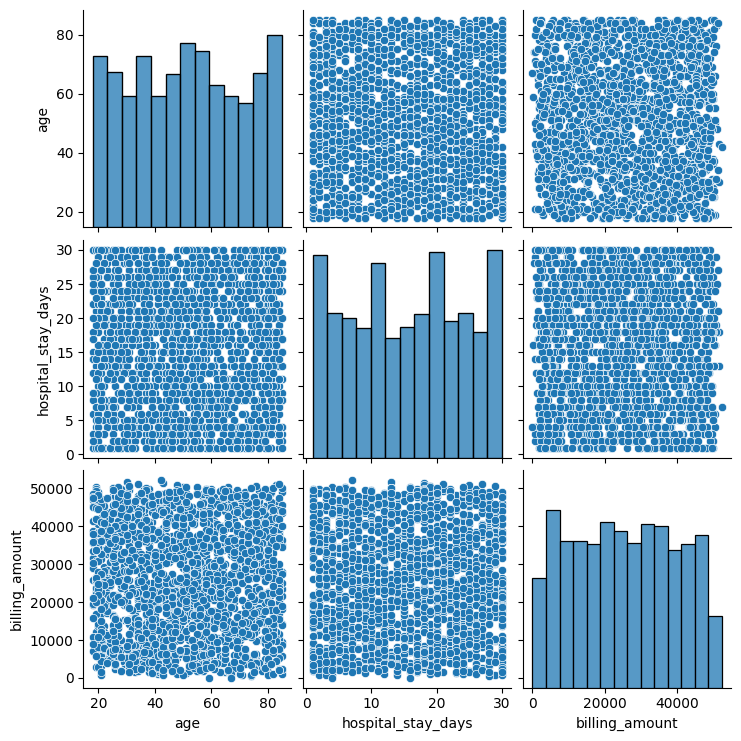

In [36]:
# Chart 10: pair plot (no plt.figure() before this one)
pair_data = df[
    ["age", "hospital_stay_days", "billing_amount"]
].dropna()
pair_data = pair_data.sample(n=min(2000, len(pair_data)), random_state=42)
sns.pairplot(pair_data)
plt.savefig("../visualizations/10_pair_plot.png", dpi=150)
plt.show()
plt.close()